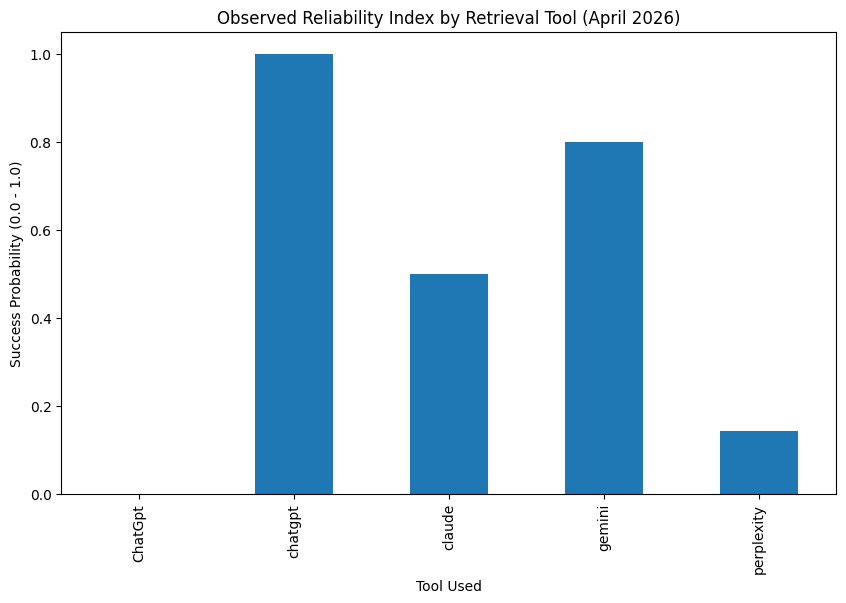

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

# Load user logs
df = pd.read_csv('llm_logs.csv')

# Create reliability column instead of replacing df
df['Reliability'] = df['Observation'].apply(
    lambda x: 1 if 'correct' in str(x).lower() 
    or 'helpful' in str(x).lower() 
    or 'clear' in str(x).lower()
    else 0
)

# Group by model
reliability_by_model = df.groupby('LLM/Google')['Reliability'].mean()

# Plot graph
plt.figure(figsize=(10,6))
reliability_by_model.plot(kind='bar')

plt.title('Observed Reliability Index by Retrieval Tool (April 2026)')
plt.ylabel('Success Probability (0.0 - 1.0)')
plt.xlabel('Tool Used')

plt.show()

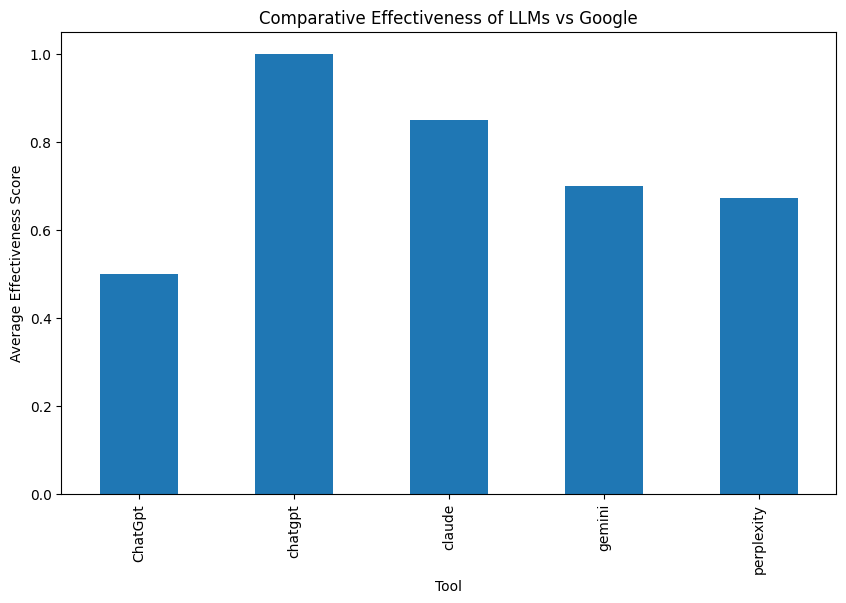

In [4]:
def score_observation(text):
    text = str(text).lower()
    
    if 'no need to switch' in text or 'clear and sufficient' in text:
        return 1
    elif 'switch to google' in text:
        return 0.5
    elif 'don\'t like' in text or 'not helpful' in text:
        return 0
    else:
        return 0.7  # neutral useful case

df['Score'] = df['Observation'].apply(score_observation)

reliability_by_model = df.groupby('LLM/Google')['Score'].mean()

plt.figure(figsize=(10,6))
reliability_by_model.plot(kind='bar')

plt.title('Comparative Effectiveness of LLMs vs Google')
plt.ylabel('Average Effectiveness Score')
plt.xlabel('Tool')

plt.show()